In [ ]:
!pip install -q torch_geometric

from google.colab import drive
drive.mount('/content/drive')   # بس إذا بدك تجيبي البيانات من Drive

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 64.4/64.4 kB 1.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 10.4 MB/s eta 0:00:00
Mounted at /content/drive


In [ ]:
import os, shutil

src_folder = '/content/drive/MyDrive/GRC/jaffe'          # المسار بعد الرفع
dst_folder = '/content/drive/MyDrive/GRC/jaffe_sorted'         # هيتنشئ تلقائيًا

code_to_class = {
    'AN': 'angry', 'DI': 'disgust', 'FE': 'fear',
    'HA': 'happy', 'NE': 'neutral', 'SA': 'sad', 'SU': 'surprise',
}

moved, skipped = 0, 0
for filename in os.listdir(src_folder):
    src_path = os.path.join(src_folder, filename)
    if not os.path.isfile(src_path):
        continue
    parts = os.path.splitext(filename)[0].split('.')
    code = parts[1][:2].upper() if len(parts) > 1 else None
    emotion = code_to_class.get(code)
    if emotion is None:
        skipped += 1
        continue
    class_dir = os.path.join(dst_folder, emotion)
    os.makedirs(class_dir, exist_ok=True)
    shutil.copy2(src_path, os.path.join(class_dir, filename))
    moved += 1

print(f"تم ترتيب {moved} صورة، وتخطي {skipped} ملف (متوقع: README_FIRST بس).")

تم ترتيب 213 صورة، وتخطي 0 ملف (متوقع: README_FIRST بس).


In [ ]:
data_folder_path = '/content/drive/MyDrive/GRC/jaffe_sorted'
label_mapping = {'fear': 1, 'angry': 2, 'happy': 3, 'sad': 4, 'surprise': 5, 'neutral': 6, 'disgust': 7}

In [ ]:
from google.colab import files
uploaded = files.upload()   # اختاري Data_Loader.py و Training.py من جهازك

Saving Data_Loader.py to Data_Loader.py
Saving Training.py to Training.py


In [ ]:
import torch
import Data_Loader

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(device)

test_size  = 0.2
val_size   = 0.1
batch_size = 18
images_per_class = -1   # JAFFE صغير (213 صورة)، ما في داعي نحددها

train_loader, test_loader, val_loader = Data_Loader.Read_Data(
    data_folder_path, label_mapping, device, images_per_class, test_size, val_size, batch_size
)

cuda
2 -1 30
6 -1 30
4 -1 31
5 -1 30
3 -1 31
1 -1 32
7 -1 29
torch.Size([213, 3, 360, 360])


In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import models
import torch_geometric.nn as geom_nn

class GCF(nn.Module):
    def __init__(self, num_classes, device, base_model='vgg16', mode='cnn+gcn'):
        super(GCF, self).__init__()
        self.mode = mode
        self.device = device
        self.base_model = base_model.lower()
        cnn_output_size = 0

        if self.base_model == 'vgg16':
            self.model = models.vgg16(pretrained=True)
            num_ftrs = self.model.classifier[-1].in_features
            self.model.classifier = nn.Sequential(*list(self.model.classifier.children())[:-1], nn.Flatten())
            cnn_output_size = 4096
        elif self.base_model == 'vgg19':
            self.model = models.vgg19(pretrained=True)
            num_ftrs = self.model.classifier[-1].in_features
            self.model.classifier = nn.Sequential(*list(self.model.classifier.children())[:-1], nn.Flatten())
            cnn_output_size = 4096
        elif self.base_model == 'resnet18':
            self.model = models.resnet18(pretrained=True)
            num_ftrs = self.model.fc.in_features
            self.model.fc = nn.Flatten()
            cnn_output_size = 512
        elif self.base_model == 'resnet34':
            self.model = models.resnet34(pretrained=True)
            num_ftrs = self.model.fc.in_features
            self.model.fc = nn.Flatten()
            cnn_output_size = 512
        elif self.base_model == 'resnet50':
            self.model = models.resnet50(pretrained=True)
            num_ftrs = self.model.fc.in_features
            self.model.fc = nn.Flatten()
            cnn_output_size = 2048
        elif self.base_model == 'densenet121':
            self.model = models.densenet121(pretrained=True)
            num_ftrs = self.model.classifier.in_features
            self.model.classifier = nn.Sequential(nn.Flatten())
            cnn_output_size = 1024
        elif self.base_model == 'densenet169':
            self.model = models.densenet169(pretrained=True)
            num_ftrs = self.model.classifier.in_features
            self.model.classifier = nn.Sequential(nn.Flatten())
            cnn_output_size = 1664
        elif self.base_model == 'densenet201':
            self.model = models.densenet201(pretrained=True)
            num_ftrs = self.model.classifier.in_features
            self.model.classifier = nn.Sequential(nn.Flatten())
            cnn_output_size = 1920
        elif self.base_model == 'efficientnet_b0':
            self.model = models.efficientnet_b0(pretrained=True)
            num_ftrs = self.model.classifier[-1].in_features
            self.model.classifier = nn.Flatten()
            cnn_output_size = 1280
        elif self.base_model == 'inception_v3':
            self.model = models.inception_v3(pretrained=True, aux_logits=True)
            num_ftrs = self.model.fc.in_features
            self.model.fc = nn.Flatten()
            cnn_output_size = 2048
        else:
            raise ValueError(f"Unsupported base model: {self.base_model}")

        gcn_output_size = 128
        if self.mode == "cnn" or self.mode == "cnn+gcn":
            self.fc_cnn = nn.Linear(num_ftrs, cnn_output_size)
        if self.mode == "gcn" or self.mode == "cnn+gcn":
            self.fc_gcn = nn.Linear(256, gcn_output_size)

        combined_output_size = cnn_output_size + gcn_output_size if mode == "cnn+gcn" else max(cnn_output_size, gcn_output_size)
        self.fc = nn.Linear(combined_output_size, 1024)
        self.fc2 = nn.Linear(1024, 512)
        self.fc3 = nn.Linear(512, num_classes)
        self.dropout = nn.Dropout(0.5)
        self.gnn = self._build_gnn_layer(cnn_output_size)

    def _build_gnn_layer(self, cnn_output_size):
        return GNNLayer(in_channels=cnn_output_size, hidden_channels=256, out_channels=256, device=self.device)

    def forward(self, images):
        images = images.to(self.device)
        cnn_features = self.model(images)

        if self.mode == "cnn" or self.mode == "cnn+gcn":
            cnn_features = cnn_features.view(cnn_features.size(0), -1)
            cnn_features = self.fc_cnn(cnn_features)

        if self.mode == "gcn" or self.mode == "cnn+gcn":
            gcn_features = self.gnn(cnn_features)
            gcn_features = gcn_features.view(gcn_features.size(0), -1)
            gcn_features = self.fc_gcn(gcn_features)

        if self.mode == "cnn+gcn":
            features = torch.cat((cnn_features, gcn_features), dim=1)
        elif self.mode == "cnn":
            features = cnn_features
        else:
            features = gcn_features

        out = self.fc(features)
        out = F.relu(self.fc2(out))
        out = self.dropout(out)
        out = self.fc3(out)
        return out

class GNNLayer(nn.Module):
    def __init__(self, in_channels, hidden_channels, out_channels, device):
        super(GNNLayer, self).__init__()
        self.conv1 = geom_nn.GraphConv(in_channels, hidden_channels)
        self.device = device
        # VERSION 3
        self.edge_index = torch.tensor(
            [[1, 0, 3, 0, 4, 0, 2, 1, 4, 1, 4, 3, 6, 3, 5, 4, 7, 4, 7, 6, 8, 7, 4, 2, 6, 4, 4, 5, 8, 4],
             [1, 0, 3, 0, 4, 0, 2, 1, 4, 1, 4, 3, 6, 3, 5, 4, 7, 4, 7, 6, 8, 7, 4, 2, 6, 4, 4, 5, 8, 4]],
            dtype=torch.long).to(self.device)

    def forward(self, x):
        return F.relu(self.conv1(x, self.edge_index))

In [ ]:
from Training import train
import torch
import torch.optim as optim
import torch.nn as nn
import os

def get_available_device():
    if torch.cuda.is_available():
        num_gpus = torch.cuda.device_count()
        print(f"Found {num_gpus} GPU(s) available.")
        for i in range(num_gpus):
            print(f"GPU {i}: {torch.cuda.get_device_name(i)}")
        gpu_choice = 0          # ← بدل 1
        device = torch.device(f"cuda:{gpu_choice}")
        print(f"Using GPU {gpu_choice}: {torch.cuda.get_device_name(gpu_choice)}")
    else:
        device = torch.device("cpu")
        print("CUDA is not available. Using CPU.")
    return device

device = get_available_device()

def gcf_train(mode, base):
    num_classes = 8
    GCF_model = GCF(num_classes, device, base_model=base, mode=mode).to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(GCF_model.parameters(), lr=0.00005, weight_decay=1e-4)
    num_epochs = 20
    train(GCF_model, device, train_loader, val_loader, num_epochs, criterion, optimizer)
    model_filename = f"FER+{mode}"
    torch.save(GCF_model.state_dict(), f"/content/drive/MyDrive/GRC/Vgg16-Raf-{model_filename}.h5")
    return GCF_model

def gcf_test(GCF_model):
    GCF_model.eval()
    criterion = nn.CrossEntropyLoss()
    with torch.no_grad():
        test_loss, correct_predictions, total_predictions = 0.0, 0, 0
        for inputs, targets in test_loader:
            inputs, targets = inputs.to(device), targets.to(device)
            outputs = GCF_model(inputs)
            loss = criterion(outputs, targets)
            test_loss += loss.item()
            _, predicted = torch.max(outputs, 1)
            correct_predictions += (predicted == targets).sum().item()
            total_predictions += targets.size(0)
    accuracy = correct_predictions / total_predictions
    print("Test Accuracy:", accuracy)
    return accuracy

Found 1 GPU(s) available.
GPU 0: Tesla T4
Using GPU 0: Tesla T4


In [ ]:
import pandas as pd

models_list = [
    'vgg16', 'vgg19', 'resnet18', 'resnet34', 'resnet50',
    'densenet121', 'densenet169', 'densenet201',
    'efficientnet_b0'
]

results = []
for base_model in models_list:
    print("\n" + "-"*40)
    print(f"Processing Model: {base_model.upper()}")
    print("-"*40)
    GCF_model = gcf_train("cnn+gcn", base_model)
    accuracy = gcf_test(GCF_model)
    results.append([base_model, "cnn+gcn", accuracy])

results_df = pd.DataFrame(results, columns=["Base Model", "Mode", "Accuracy (%)"])
results_df.to_excel("/content/drive/MyDrive/GRC/model_results.xlsx", index=False)
print("\nFinal Results:")
print(results_df.to_string(index=False))


----------------------------------------
Processing Model: VGG16
----------------------------------------


/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=VGG16_Weights.IMAGENET1K_V1`. You can also use `weights=VGG16_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Downloading: "https://download.pytorch.org/models/vgg16-397923af.pth" to /root/.cache/torch/hub/checkpoints/vgg16-397923af.pth


100%|██████████| 528M/528M [00:04<00:00, 135MB/s]


Epoch 1/20, Train Loss: 2.06, Train Acc: 11.81%, Val Loss: 2.01, Val Acc: 22.22%
Epoch 2/20, Train Loss: 1.98, Train Acc: 17.36%, Val Loss: 1.97, Val Acc: 16.67%
Epoch 3/20, Train Loss: 1.92, Train Acc: 23.61%, Val Loss: 1.84, Val Acc: 27.78%
Epoch 4/20, Train Loss: 1.84, Train Acc: 28.47%, Val Loss: 1.79, Val Acc: 16.67%
Epoch 5/20, Train Loss: 1.65, Train Acc: 39.58%, Val Loss: 1.88, Val Acc: 11.11%
Epoch 6/20, Train Loss: 1.52, Train Acc: 41.67%, Val Loss: 1.62, Val Acc: 27.78%
Epoch 7/20, Train Loss: 1.37, Train Acc: 47.22%, Val Loss: 1.54, Val Acc: 38.89%
Epoch 8/20, Train Loss: 1.10, Train Acc: 56.94%, Val Loss: 1.08, Val Acc: 55.56%
Epoch 9/20, Train Loss: 0.87, Train Acc: 61.81%, Val Loss: 0.74, Val Acc: 77.78%
Epoch 10/20, Train Loss: 0.56, Train Acc: 77.78%, Val Loss: 0.58, Val Acc: 77.78%
Epoch 11/20, Train Loss: 0.40, Train Acc: 84.03%, Val Loss: 0.62, Val Acc: 77.78%
Epoch 12/20, Train Loss: 0.34, Train Acc: 84.72%, Val Loss: 0.59, Val Acc: 77.78%
Epoch 13/20, Train Loss: 

/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=VGG19_Weights.IMAGENET1K_V1`. You can also use `weights=VGG19_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


... (21 outputs left out)

100%|██████████| 77.4M/77.4M [00:00<00:00, 104MB/s] 


Epoch 1/20, Train Loss: 2.05, Train Acc: 11.81%, Val Loss: 2.05, Val Acc: 5.56%
Epoch 2/20, Train Loss: 1.94, Train Acc: 19.44%, Val Loss: 2.02, Val Acc: 5.56%
Epoch 3/20, Train Loss: 1.78, Train Acc: 30.56%, Val Loss: 1.99, Val Acc: 5.56%
Epoch 4/20, Train Loss: 1.54, Train Acc: 40.97%, Val Loss: 1.94, Val Acc: 5.56%
Epoch 5/20, Train Loss: 1.32, Train Acc: 62.50%, Val Loss: 1.77, Val Acc: 16.67%
Epoch 6/20, Train Loss: 1.09, Train Acc: 68.75%, Val Loss: 1.48, Val Acc: 50.00%
Epoch 7/20, Train Loss: 0.84, Train Acc: 80.56%, Val Loss: 1.22, Val Acc: 55.56%
Epoch 8/20, Train Loss: 0.63, Train Acc: 82.64%, Val Loss: 1.02, Val Acc: 66.67%
Epoch 9/20, Train Loss: 0.45, Train Acc: 88.89%, Val Loss: 0.98, Val Acc: 77.78%
Epoch 10/20, Train Loss: 0.28, Train Acc: 95.14%, Val Loss: 0.94, Val Acc: 55.56%
Epoch 11/20, Train Loss: 0.22, Train Acc: 95.14%, Val Loss: 0.62, Val Acc: 77.78%
Epoch 12/20, Train Loss: 0.21, Train Acc: 93.06%, Val Loss: 0.54, Val Acc: 83.33%
Epoch 13/20, Train Loss: 0.12

/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=EfficientNet_B0_Weights.IMAGENET1K_V1`. You can also use `weights=EfficientNet_B0_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)
100%|██████████| 20.5M/20.5M [00:00<00:00, 127MB/s]


Epoch 1/20, Train Loss: 2.07, Train Acc: 14.58%, Val Loss: 2.08, Val Acc: 16.67%
Epoch 2/20, Train Loss: 2.03, Train Acc: 25.69%, Val Loss: 2.08, Val Acc: 16.67%
Epoch 3/20, Train Loss: 1.98, Train Acc: 31.25%, Val Loss: 2.07, Val Acc: 16.67%
Epoch 4/20, Train Loss: 1.93, Train Acc: 28.47%, Val Loss: 2.06, Val Acc: 22.22%
Epoch 5/20, Train Loss: 1.84, Train Acc: 30.56%, Val Loss: 1.99, Val Acc: 16.67%
Epoch 6/20, Train Loss: 1.76, Train Acc: 36.81%, Val Loss: 1.98, Val Acc: 11.11%
Epoch 7/20, Train Loss: 1.62, Train Acc: 53.47%, Val Loss: 1.89, Val Acc: 16.67%
Epoch 8/20, Train Loss: 1.43, Train Acc: 63.89%, Val Loss: 1.74, Val Acc: 27.78%
Epoch 9/20, Train Loss: 1.21, Train Acc: 65.97%, Val Loss: 1.57, Val Acc: 38.89%
Epoch 10/20, Train Loss: 0.94, Train Acc: 74.31%, Val Loss: 1.23, Val Acc: 61.11%
Epoch 11/20, Train Loss: 0.68, Train Acc: 87.50%, Val Loss: 0.94, Val Acc: 61.11%
Epoch 12/20, Train Loss: 0.52, Train Acc: 85.42%, Val Loss: 0.84, Val Acc: 72.22%
Epoch 13/20, Train Loss: 

/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=VGG16_Weights.IMAGENET1K_V1`. You can also use `weights=VGG16_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Epoch 1: Train 11.8% | Val 22.2%
Epoch 2: Train 13.2% | Val 16.7%
Epoch 3: Train 19.4% | Val 27.8%
Epoch 4: Train 25.0% | Val 33.3%
Epoch 5: Train 37.5% | Val 38.9%
Epoch 6: Train 55.6% | Val 61.1%
Epoch 7: Train 57.6% | Val 55.6%
Epoch 8: Train 67.4% | Val 72.2%
Epoch 9: Train 81.9% | Val 77.8%
Epoch 10: Train 84.7% | Val 61.1%
Epoch 11: Train 81.9% | Val 83.3%
Epoch 12: Train 85.4% | Val 83.3%
Epoch 13: Train 94.4% | Val 77.8%
Epoch 14: Train 95.8% | Val 83.3%
Epoch 15: Train 98.6% | Val 83.3%
Epoch 16: Train 100.0% | Val 88.9%
Epoch 17: Train 98.6% | Val 88.9%
Epoch 18: Train 98.6% | Val 72.2%
Epoch 19: Train 97.2% | Val 72.2%
Epoch 20: Train 96.5% | Val 94.4%


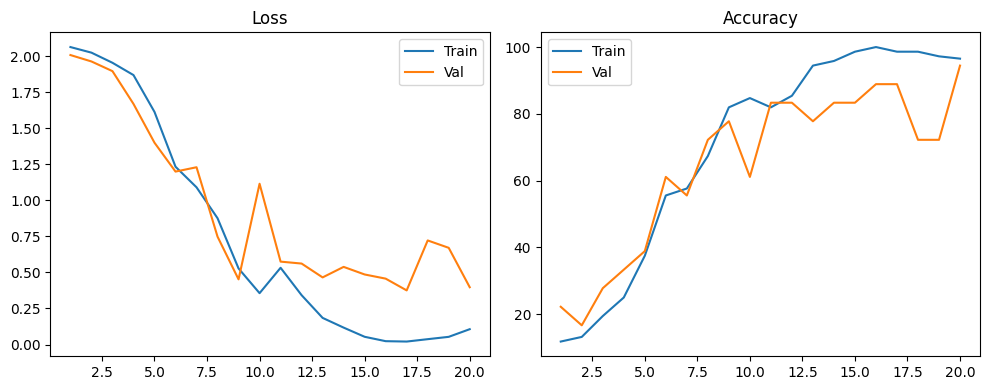

In [ ]:
def train_with_history(GCF_model, device, train_loader, val_loader, num_epochs, criterion, optimizer):
    history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
    for epoch in range(num_epochs):
        GCF_model.train()
        correct, total, loss_sum = 0, 0, 0
        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = GCF_model(images)
            loss = criterion(outputs, labels)
            optimizer.zero_grad(); loss.backward(); optimizer.step()
            _, predicted = torch.max(outputs, 1)
            correct += (predicted == labels).sum().item()
            total += labels.size(0)
            loss_sum += loss.item()
        history["train_loss"].append(loss_sum/len(train_loader))
        history["train_acc"].append(100*correct/total)

        GCF_model.eval()
        correct, total, loss_sum = 0, 0, 0
        with torch.no_grad():
            for images, labels in val_loader:
                images, labels = images.to(device), labels.to(device)
                outputs = GCF_model(images)
                loss = criterion(outputs, labels)
                _, predicted = torch.max(outputs, 1)
                correct += (predicted == labels).sum().item()
                total += labels.size(0)
                loss_sum += loss.item()
        history["val_loss"].append(loss_sum/len(val_loader))
        history["val_acc"].append(100*correct/total)
        print(f"Epoch {epoch+1}: Train {history['train_acc'][-1]:.1f}% | Val {history['val_acc'][-1]:.1f}%")
    return history

# تشغيل ورسم
GCF_model = GCF(num_classes=8, device=device, base_model='vgg16', mode='cnn+gcn').to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(GCF_model.parameters(), lr=0.00005, weight_decay=1e-4)
history = train_with_history(GCF_model, device, train_loader, val_loader, 20, criterion, optimizer)

import matplotlib.pyplot as plt
epochs = range(1, 21)
plt.figure(figsize=(10,4))
plt.subplot(1,2,1); plt.plot(epochs, history["train_loss"], label="Train"); plt.plot(epochs, history["val_loss"], label="Val"); plt.title("Loss"); plt.legend()
plt.subplot(1,2,2); plt.plot(epochs, history["train_acc"], label="Train"); plt.plot(epochs, history["val_acc"], label="Val"); plt.title("Accuracy"); plt.legend()
plt.tight_layout()
plt.savefig("/content/drive/MyDrive/GRC/vgg16_curves.png"); plt.show()

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

models_list = ['vgg16', 'vgg19', 'resnet18', 'resnet34', 'resnet50',
                'densenet121', 'densenet169', 'densenet201', 'efficientnet_b0']

comparison = []
for base_model in models_list:
    cnn_model = gcf_train("cnn", base_model)
    cnn_acc = gcf_test(cnn_model)
    gcf_model = gcf_train("cnn+gcn", base_model)
    gcf_acc = gcf_test(gcf_model)
    comparison.append([base_model, cnn_acc, gcf_acc])

comp_df = pd.DataFrame(comparison, columns=["Base Model", "CNN only", "CNN+GCN"])
comp_df.to_excel("/content/drive/MyDrive/GRC/cnn_vs_gcf.xlsx", index=False)

x = range(len(comp_df))
plt.figure(figsize=(10,5))
plt.bar([i-0.2 for i in x], comp_df["CNN only"], width=0.4, label="CNN فقط")
plt.bar([i+0.2 for i in x], comp_df["CNN+GCN"], width=0.4, label="CNN+GCN")
plt.xticks(x, comp_df["Base Model"], rotation=45)
plt.ylabel("Test Accuracy"); plt.title("أثر طبقة الغراف على الدقة"); plt.legend()
plt.tight_layout(); plt.savefig("/content/drive/MyDrive/GRC/cnn_vs_gcf_chart.png"); plt.show()

Epoch 1/20, Train Loss: 2.07, Train Acc: 12.50%, Val Loss: 2.03, Val Acc: 5.56%
Epoch 2/20, Train Loss: 1.96, Train Acc: 17.36%, Val Loss: 1.89, Val Acc: 38.89%
Epoch 3/20, Train Loss: 1.84, Train Acc: 22.92%, Val Loss: 1.65, Val Acc: 44.44%
Epoch 4/20, Train Loss: 1.62, Train Acc: 32.64%, Val Loss: 1.32, Val Acc: 61.11%
Epoch 5/20, Train Loss: 1.59, Train Acc: 38.19%, Val Loss: 1.14, Val Acc: 66.67%
Epoch 6/20, Train Loss: 1.40, Train Acc: 46.53%, Val Loss: 1.42, Val Acc: 38.89%
Epoch 7/20, Train Loss: 1.12, Train Acc: 56.94%, Val Loss: 1.02, Val Acc: 50.00%
Epoch 8/20, Train Loss: 0.88, Train Acc: 65.97%, Val Loss: 0.75, Val Acc: 61.11%
Epoch 9/20, Train Loss: 0.67, Train Acc: 73.61%, Val Loss: 0.54, Val Acc: 88.89%
Epoch 10/20, Train Loss: 0.54, Train Acc: 80.56%, Val Loss: 0.90, Val Acc: 55.56%
Epoch 11/20, Train Loss: 0.40, Train Acc: 86.11%, Val Loss: 0.83, Val Acc: 72.22%
Epoch 12/20, Train Loss: 0.41, Train Acc: 86.11%, Val Loss: 0.34, Val Acc: 88.89%
Epoch 13/20, Train Loss: 0

KeyboardInterrupt: 

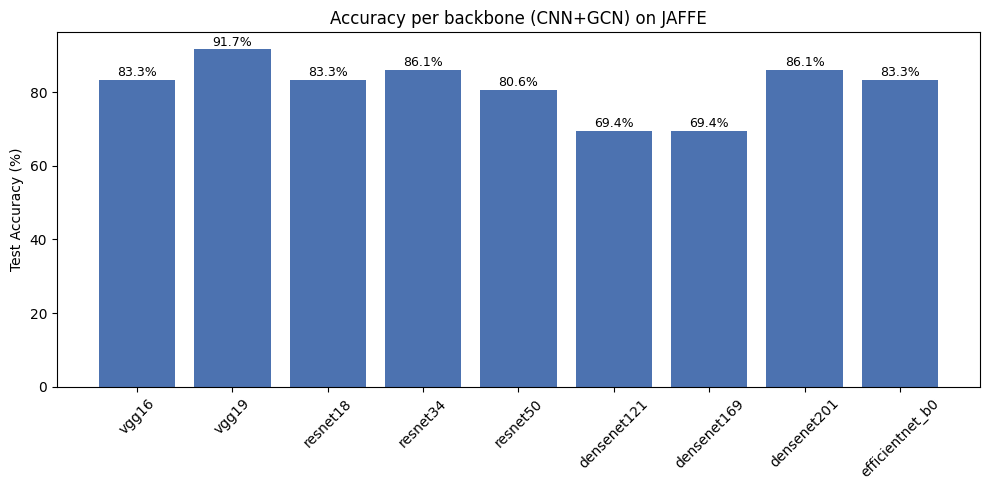

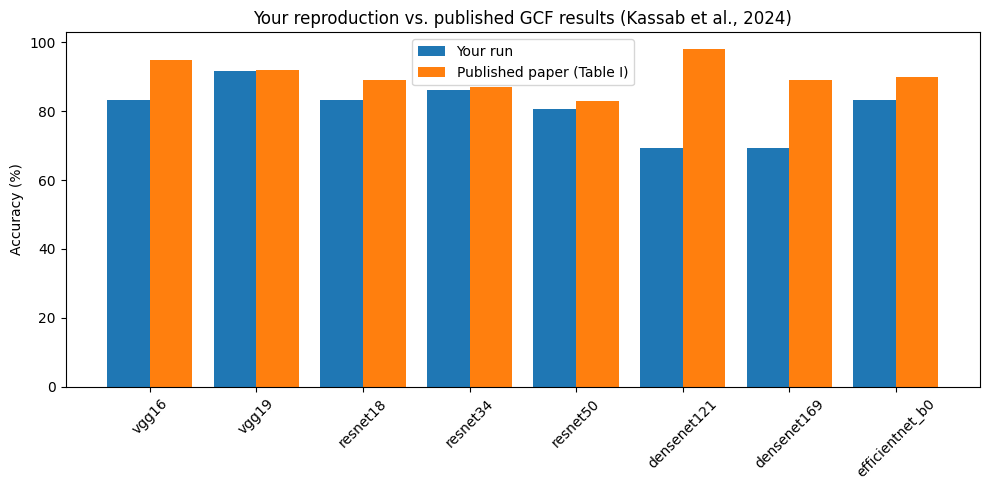

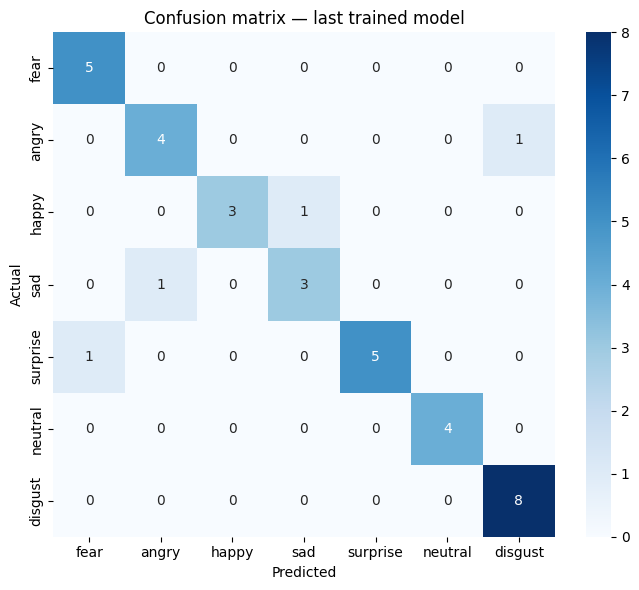


Summary table:
     Base Model    Mode  Accuracy (%)
          vgg16 cnn+gcn     83.333333
          vgg19 cnn+gcn     91.666667
       resnet18 cnn+gcn     83.333333
       resnet34 cnn+gcn     86.111111
       resnet50 cnn+gcn     80.555556
    densenet121 cnn+gcn     69.444444
    densenet169 cnn+gcn     69.444444
    densenet201 cnn+gcn     86.111111
efficientnet_b0 cnn+gcn     83.333333


In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# تحميل النتائج (لو مو موجودة بالذاكرة، اقرئيها من Drive)
try:
    results_df
except NameError:
    results_df = pd.read_excel("/content/drive/MyDrive/GRC/model_results.xlsx")

acc_col = "Accuracy (%)"
if results_df[acc_col].max() <= 1:          # الكود الأصلي بيخزن نسبة (0-1) مو نسبة مئوية
    results_df[acc_col] = results_df[acc_col] * 100

# 1) دقة كل Backbone
plt.figure(figsize=(10,5))
bars = plt.bar(results_df["Base Model"], results_df[acc_col], color="#4C72B0")
plt.ylabel("Test Accuracy (%)")
plt.title("Accuracy per backbone (CNN+GCN) on JAFFE")
plt.xticks(rotation=45)
for bar, val in zip(bars, results_df[acc_col]):
    plt.text(bar.get_x()+bar.get_width()/2, val+1, f"{val:.1f}%", ha="center", fontsize=9)
plt.tight_layout()
plt.savefig("/content/drive/MyDrive/GRC/accuracy_per_model.png")
plt.show()

# 2) مقارنة بالأرقام المنشورة رسميًا (Table I بالورقة نفسها - JAFFE)
paper_gcf = {
    'vgg16': 95, 'vgg19': 92, 'resnet18': 89, 'resnet34': 87,
    'resnet50': 83, 'efficientnet_b0': 90, 'densenet121': 98, 'densenet169': 89.2,
}   # densenet201 مو موجود بجدول الورقة، رح يتجاهله تلقائيًا

compare_models = [m for m in results_df["Base Model"] if m in paper_gcf]
your_acc  = [results_df.loc[results_df["Base Model"]==m, acc_col].values[0] for m in compare_models]
paper_acc = [paper_gcf[m] for m in compare_models]

x = np.arange(len(compare_models))
plt.figure(figsize=(10,5))
plt.bar(x-0.2, your_acc,  width=0.4, label="Your run")
plt.bar(x+0.2, paper_acc, width=0.4, label="Published paper (Table I)")
plt.xticks(x, compare_models, rotation=45)
plt.ylabel("Accuracy (%)")
plt.title("Your reproduction vs. published GCF results (Kassab et al., 2024)")
plt.legend()
plt.tight_layout()
plt.savefig("/content/drive/MyDrive/GRC/vs_paper_comparison.png")
plt.show()

# 3) مصفوفة الالتباس — لآخر موديل مدرَّب بالذاكرة
from sklearn.metrics import confusion_matrix
import seaborn as sns

GCF_model.eval()
all_preds, all_labels = [], []
with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = GCF_model(images)
        _, preds = torch.max(outputs, 1)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

class_names = ['fear', 'angry', 'happy', 'sad', 'surprise', 'neutral', 'disgust']
cm = confusion_matrix(all_labels, all_preds, labels=list(range(1,8)))

plt.figure(figsize=(7,6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Predicted"); plt.ylabel("Actual")
plt.title("Confusion matrix — last trained model")
plt.tight_layout()
plt.savefig("/content/drive/MyDrive/GRC/confusion_matrix.png")
plt.show()

print("\nSummary table:")
print(results_df.to_string(index=False))